# Base 1: exploração, ACF, STL e tratamento

Este notebook transforma apenas a entrada estrutural da Base 1 em um CSV `cleaned`, sem alterar os arquivos congelados. A ACF e a STL usam o maior segmento regular e completo do alvo, sem preencher ausências somente para gerar gráfico.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "configs").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from discovery_series_temporais.cleaning import build_cleaned_dataset, plot_cleaned_diagnostics

BASE_ID = 1
cleaned, summary = build_cleaned_dataset(BASE_ID, ROOT / "data" / "processed")
display(pd.DataFrame([{
    "base": summary.base_id,
    "target_original": summary.target_name,
    "rows": summary.rows,
    "columns": summary.columns,
    "missing_target": summary.missing_target,
    "cleaned_output": str(summary.output_path),
    "actions": "; ".join(summary.actions),
}]))
display(cleaned.head())
display(cleaned.isna().sum().rename("missing_values").to_frame())


,base,target_original,rows,columns,missing_target,cleaned_output,actions
0,1,Close,2836,6,0,C:\Users\mayumishimizu-ieg\.codex\.chatgpt-pro...,retained daily OHLCV values; renamed Close to ...


,timestamp,target,Open,High,Low,Volume
0,2017-01-01,998.325012,963.658020,1003.080017,958.698975,147775008
1,2017-01-02,1021.750000,998.617004,1031.390015,996.702026,222184992
2,2017-01-03,1043.839966,1021.599976,1044.079956,1021.599976,185168000
3,2017-01-04,1154.729980,1044.400024,1159.420044,1044.400024,344945984
4,2017-01-05,1013.380005,1156.729980,1191.099976,910.416992,510199008


,missing_values
timestamp,0
target,0
Open,0
High,0
Low,0
Volume,0


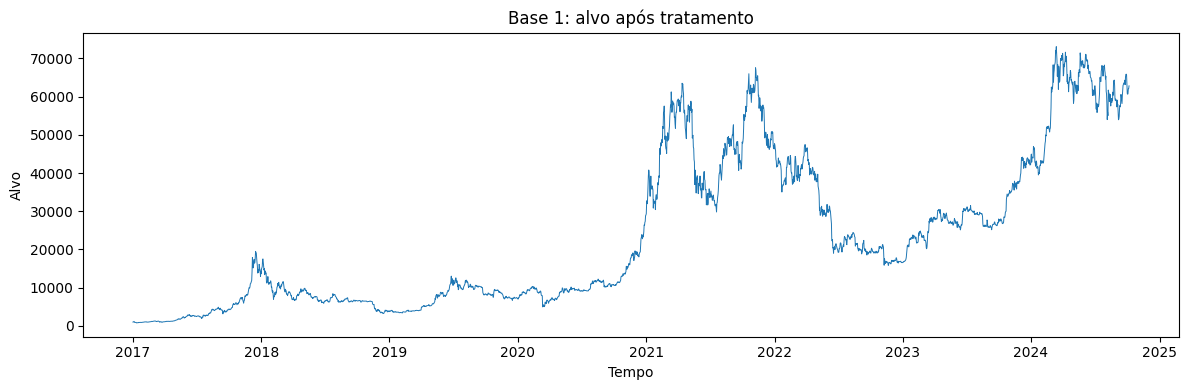

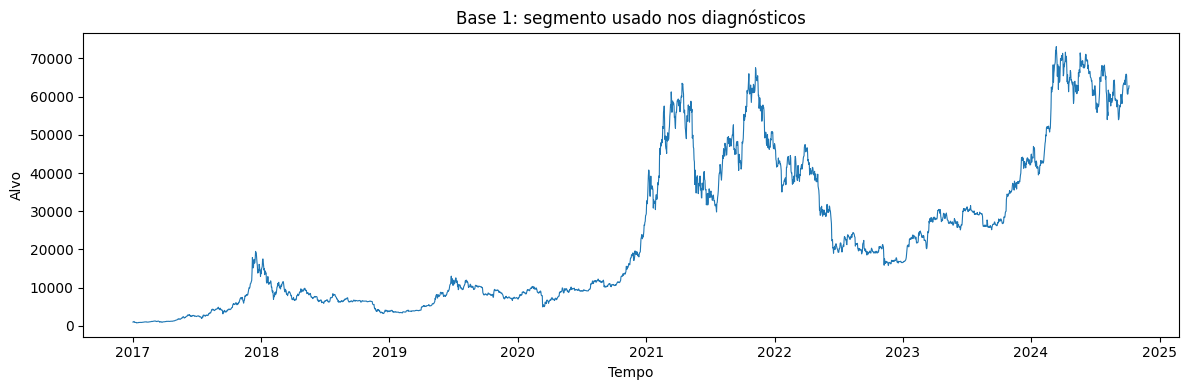

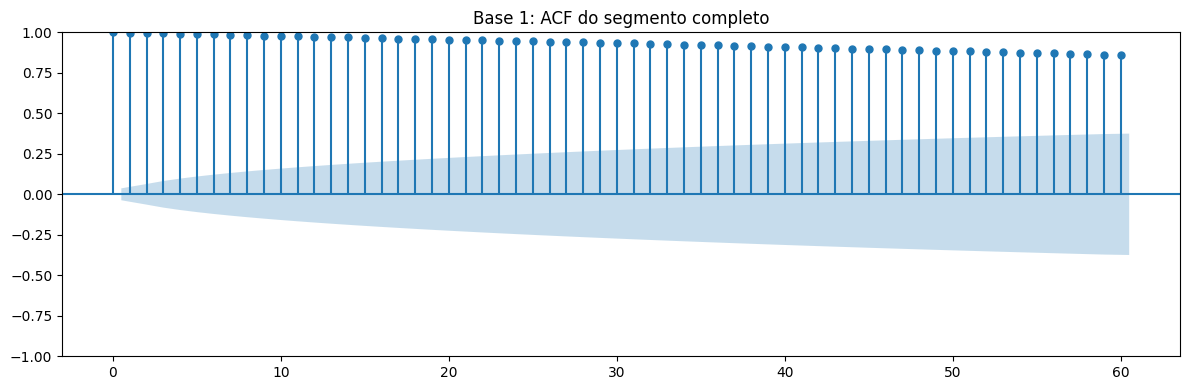

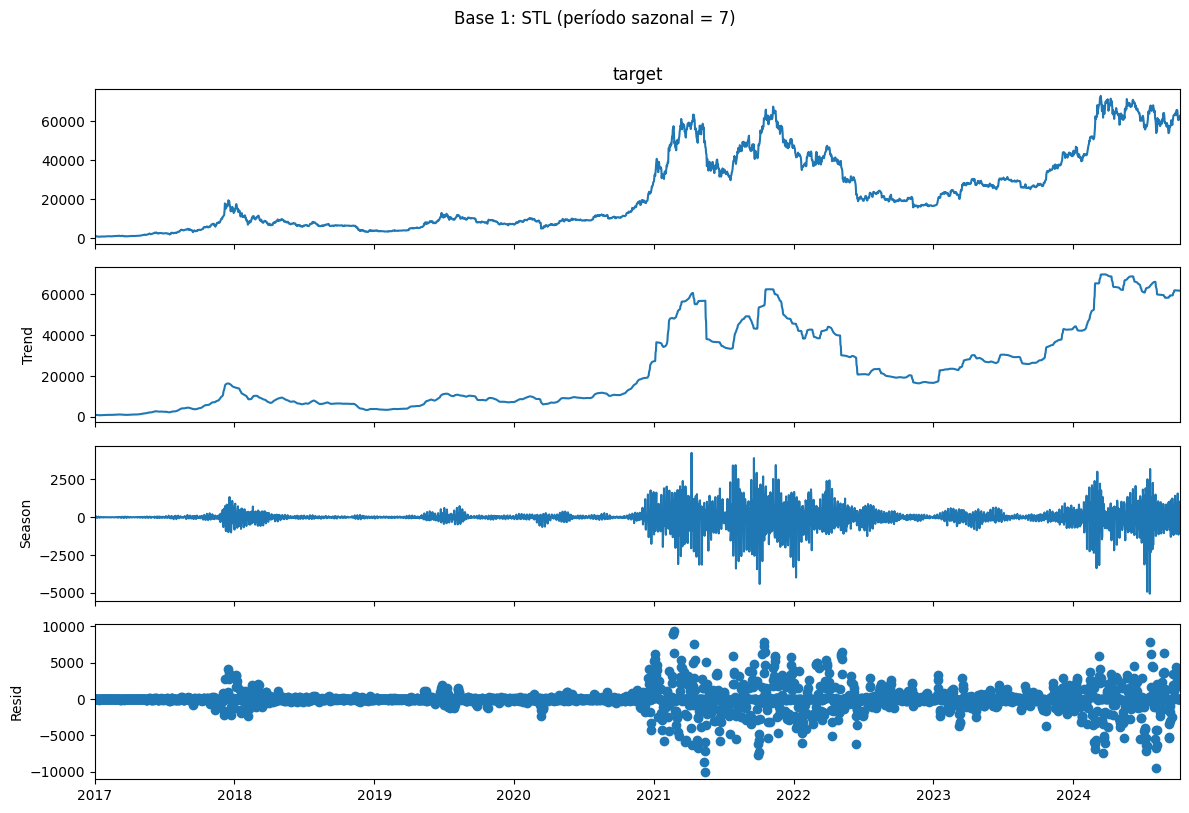

,segment_start,segment_end,segment_points,stl_seasonal_period,acf_lags
0,2017-01-01,2024-10-06,2836,7,60


In [2]:
figure, axis = plt.subplots(figsize=(12, 4))
axis.plot(cleaned["timestamp"], cleaned["target"], linewidth=0.7)
axis.set(title=f"Base {BASE_ID}: alvo após tratamento", xlabel="Tempo", ylabel="Alvo")
figure.tight_layout()
plt.show()

diagnostic = plot_cleaned_diagnostics(
    cleaned,
    BASE_ID,
    ROOT / "reports" / "generated" / "exploration" / f"base{BASE_ID}",
)
display(pd.DataFrame([{
    "segment_start": diagnostic.data["timestamp"].min(),
    "segment_end": diagnostic.data["timestamp"].max(),
    "segment_points": len(diagnostic.data),
    "stl_seasonal_period": diagnostic.seasonal_period,
    "acf_lags": diagnostic.acf_lags,
}]))
